# Predicción de la posición habitual de un jugador de fútbol
## 03 · Modelado (aprendizaje supervisado y exploración no supervisada)

Proyecto final de Sistemas Inteligentes · UNAM · Matemáticas Aplicadas y Computación

## Objetivo

Entrenar **varios modelos** que predigan la **posición habitual** de una persona (siete clases) a partir de sus autoevaluaciones y de su experiencia, **compararlos con métricas adecuadas** y dejar guardado el modelo final para la aplicación web.

## ¿Por qué es aprendizaje supervisado?

Porque **conocemos la respuesta**: cada persona dijo en qué posición juega (la variable objetivo). Entrenamos al modelo con ejemplos "características → posición" y medimos si acierta con personas que no vio. Los datos lo permiten: las siete posiciones tienen entre 27 y 53 personas cada una, así que no hace falta fusionar clases.

El **aprendizaje no supervisado** (agrupar sin usar la posición) se incluye solo como **exploración**, al final: sirve para ver si las habilidades, por sí solas, forman grupos parecidos a las posiciones.

## Cuidados que tomamos

| Cuidado | Por qué |
|---|---|
| **Validación cruzada estratificada y repetida** (5 pliegues × 2 repeticiones) | Con ~270 personas, un solo corte entrenamiento/prueba daría un resultado muy dependiente del azar. Estratificada = cada pliegue conserva la proporción de cada posición. |
| **Validación anidada** | Los hiperparámetros se buscan **solo con los datos de entrenamiento** de cada pliegue (búsqueda interna). Así el resultado que reportamos no está inflado por haber "afinado con las respuestas del examen". |
| **Todo el preprocesamiento dentro de la tubería** (imputar, escalar, PCA) | Evita fuga de información: nada se calcula con la persona que se evalúa. |
| **Modelo base** | Si un modelo no supera al que siempre responde la posición más común, no aprendió nada útil. |
| **Métricas para clases desbalanceadas** | Usamos aciertos balanceados y **F1 macro** (promedia todas las posiciones por igual), además de los aciertos. |
| **Sin fusionar clases ni tocar la variable objetivo** | Lo pidió la maestra: no se cambian las categorías para "mejorar" resultados. |
| **PCA con y sin** | La maestra lo recomendó. PCA resume variables, pero hace más difícil explicar el resultado, así que se compara. |

## Cómo leer las métricas

| Métrica | Qué significa | Referencia |
|---|---|---|
| Aciertos | % de personas con la posición correcta | Azar = 14.3 %; base ≈ 19.5 % |
| Aciertos balanceados | Promedio del acierto en cada posición | Azar ≈ 14.3 % |
| **F1 macro** | Equilibrio entre precisión y sensibilidad, promediado entre posiciones | Es la métrica con la que **elegimos** el mejor modelo |
| Top-2 | % de veces que la posición real está entre las **dos** que el modelo considera más probables | Útil porque algunas posiciones se parecen |
| Pérdida logarítmica | Qué tan buenas son las **probabilidades** (menor es mejor) | |

## Una advertencia importante

Las habilidades son **autoevaluaciones**: quien juega de portero se describe con buenos reflejos *porque* es portero. Es probable que algunas posiciones se identifiquen muy bien por eso, y esto **no demuestra** que el modelo mida habilidades reales. Además, la muestra es sobre todo de jugadores recreativos.

## Datos

Usamos `Datos_Limpios.csv` (lo genera el cuaderno 01). Este cuaderno puede tardar **varios minutos** en la sección de comparación de modelos.

### Los modelos que probamos y por qué

| Modelo | Qué hace | Por qué lo probamos |
|---|---|---|
| **Base** | Siempre responde la posición más común | Punto de comparación mínimo |
| **k vecinos (Nearest Neighbors)** | Compara a la persona con las *k* más parecidas y vota | Es el algoritmo visto en clase y es muy intuitivo: "quien se parece a ti, juega donde tú" |
| **Regresión logística** | Suma el peso de cada habilidad para calcular la probabilidad de cada posición | Sencillo, se puede explicar y da probabilidades |
| **SVM (máquina de vectores de soporte)** | Busca fronteras suaves que separen las posiciones (sus probabilidades se calibran con un paso adicional) | Funciona bien con pocos datos y variables correlacionadas |
| **Árbol de decisión** | Hace preguntas de sí/no ("¿regate ≥ 4?") | Es muy fácil de interpretar |
| **Bosque aleatorio** | Muchos árboles que votan | Más estable que un solo árbol y capta relaciones no lineales |
| **k vecinos, regresión logística y SVM + PCA** | Los mismos modelos pero sobre componentes principales | Para comparar **con y sin PCA** |

Todos tienen sentido para **clasificación de varias clases**. No usamos redes neuronales: con ~270 personas no hay datos suficientes para justificarlas.

### Preparar el entorno
*Qué hace:* importa las herramientas, revisa si estamos en Google Colab y muestra las versiones (importa porque el modelo guardado debe cargarse con la **misma** versión de scikit-learn).

In [1]:
import json
import os
import platform
import shutil
import time
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, balanced_accuracy_score, confusion_matrix, f1_score,
    log_loss, normalized_mutual_info_score, precision_recall_fscore_support, silhouette_score,
    top_k_accuracy_score,
)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

try:
    from google.colab import files  # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

try:
    from IPython.display import display
except ImportError:
    display = print

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| joblib", joblib.__version__, "| Colab:", EN_COLAB)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | joblib 1.6.0 | Colab: True


### Cargar los datos
*Qué hace:* busca `Datos_Limpios.csv` (si no está, te pide subirlo) y lo lee.

In [2]:
ARCHIVO = "Datos_Limpios.csv"

if not os.path.exists(ARCHIVO):
    if EN_COLAB:
        print("Elige el archivo Datos_Limpios.csv en la ventana que se abre...")
        files.upload()
    if not os.path.exists(ARCHIVO):
        raise FileNotFoundError(
            f"No se encontró '{ARCHIVO}'. Súbelo al panel de archivos de Colab con ese nombre exacto."
        )

datos = pd.read_csv(ARCHIVO, encoding="utf-8-sig")

HABILIDADES = [
    "velocidad", "resistencia", "fuerza", "control_balon", "regate", "pase",
    "definicion", "defensa", "juego_aereo", "vision_juego", "reflejos", "posicionamiento",
]
NOMBRES = {
    "velocidad": "Velocidad", "resistencia": "Resistencia", "fuerza": "Fuerza",
    "control_balon": "Control del balón", "regate": "Regate", "pase": "Pase",
    "definicion": "Definición", "defensa": "Defensa", "juego_aereo": "Juego aéreo",
    "vision_juego": "Visión de juego", "reflejos": "Reflejos", "posicionamiento": "Posicionamiento",
    "edad": "Edad", "tiempo_codigo": "Tiempo jugando", "horas_codigo": "Horas por semana", "nivel": "Nivel",
}
ORDEN_POSICION = [
    "Portero", "Defensa central", "Lateral", "Mediocampista defensivo",
    "Mediocampista ofensivo", "Extremo", "Delantero",
]
CLASES = sorted(ORDEN_POSICION)  # el orden en que scikit-learn guarda las clases

assert set(datos["posicion"].unique()) == set(ORDEN_POSICION)
assert datos["id_persona"].is_unique

conteo = datos["posicion"].value_counts()
azar = 1 / len(CLASES)
base = conteo.max() / len(datos)
print(f"Personas: {len(datos)} | Posiciones: {len(CLASES)} | Menos casos: {conteo.idxmin()} ({conteo.min()})")
print(f"Azar: {azar:.1%} | Modelo base (siempre '{conteo.idxmax()}'): {base:.1%}")

Personas: 272 | Posiciones: 7 | Menos casos: Extremo (27)
Azar: 14.3% | Modelo base (siempre 'Defensa central'): 19.5%


## 1. Preparar las herramientas de evaluación

*Qué hace:* define cómo se miden los modelos y cómo se arma cada uno. Tres decisiones importantes:

- **Una sola forma de predecir:** la posición que el modelo considera **más probable** (el máximo de sus probabilidades). Así lo que medimos aquí es exactamente lo que hará la aplicación web.
- **Tubería (pipeline):** cada modelo recibe primero el preprocesamiento (rellenar los "No sé" con la mediana, escalar, y PCA en las variantes que lo usan). Todo se aprende **solo con los datos de entrenamiento** de cada pliegue.
- **Dos validaciones:** una **externa** (la que reportamos) y una **interna** (solo para elegir hiperparámetros).

In [3]:
N_PLIEGUES = 5
CV_EXTERNA = RepeatedStratifiedKFold(n_splits=N_PLIEGUES, n_repeats=2, random_state=42)
CV_INTERNA = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)


def prediccion(estimador, X):
    # La posición más probable según el modelo.
    proba = estimador.predict_proba(X)
    return estimador.classes_[np.argmax(proba, axis=1)], proba


def puntaje_f1_macro(estimador, X, y):
    pred, _ = prediccion(estimador, X)
    return f1_score(y, pred, average="macro", zero_division=0)


def puntaje_exactitud(estimador, X, y):
    pred, _ = prediccion(estimador, X)
    return accuracy_score(y, pred)


def puntaje_balanceado(estimador, X, y):
    pred, _ = prediccion(estimador, X)
    return balanced_accuracy_score(y, pred)


def preprocesador(numericas, categoricas, escalar):
    pasos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalar", StandardScaler()))
    transformadores = [("num", Pipeline(pasos), numericas)]
    if categoricas:
        transformadores.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas))
    return ColumnTransformer(transformadores)


def tuberia(modelo, numericas, categoricas, escalar, pca=False):
    pasos = [("prep", preprocesador(numericas, categoricas, escalar))]
    if pca:
        pasos.append(("pca", PCA(random_state=0)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def especificaciones(numericas, categoricas):
    # Cada modelo: (tubería, rejilla de hiperparámetros o None si no se ajusta).
    def t(modelo, escalar, pca=False):
        return tuberia(modelo, numericas, categoricas, escalar, pca)

    return {
        "Base (siempre la posición más común)": (t(DummyClassifier(strategy="prior"), False), None),
        "k vecinos": (
            t(KNeighborsClassifier(), True),
            {"modelo__n_neighbors": [3, 5, 7, 11, 15, 21], "modelo__weights": ["uniform", "distance"]},
        ),
        "Regresión logística": (
            t(LogisticRegression(max_iter=2000), True),
            {"modelo__C": [0.01, 0.1, 1, 10]},
        ),
        "SVM": (
            t(CalibratedClassifierCV(SVC(kernel="rbf", random_state=0), method="sigmoid", cv=3, ensemble=False), True),
            {"modelo__estimator__C": [0.3, 1, 3, 10], "modelo__estimator__gamma": ["scale", 0.02]},
        ),
        "Árbol de decisión": (
            t(DecisionTreeClassifier(random_state=0), False),
            {"modelo__max_depth": [3, 4, 5, 6, 8], "modelo__min_samples_leaf": [1, 3, 5]},
        ),
        "Bosque aleatorio": (
            t(RandomForestClassifier(n_estimators=200, random_state=0), False),
            {"modelo__max_depth": [4, 6, None], "modelo__min_samples_leaf": [1, 3]},
        ),
        "k vecinos + PCA": (
            t(KNeighborsClassifier(), True, pca=True),
            {"pca__n_components": [4, 6, 8], "modelo__n_neighbors": [5, 11, 21], "modelo__weights": ["uniform", "distance"]},
        ),
        "Regresión logística + PCA": (
            t(LogisticRegression(max_iter=2000), True, pca=True),
            {"pca__n_components": [4, 6, 8], "modelo__C": [0.1, 1, 10]},
        ),
        "SVM + PCA": (
            t(CalibratedClassifierCV(SVC(kernel="rbf", random_state=0), method="sigmoid", cv=3, ensemble=False), True, pca=True),
            {"pca__n_components": [4, 6, 8], "modelo__estimator__C": [1, 10]},
        ),
    }


def estimador(nombre, numericas, categoricas):
    tuberia_base, rejilla = especificaciones(numericas, categoricas)[nombre]
    if rejilla is None:
        return tuberia_base
    return GridSearchCV(tuberia_base, rejilla, scoring=puntaje_f1_macro, cv=CV_INTERNA, n_jobs=1, refit=True)


MODELOS = list(especificaciones(HABILIDADES, []).keys())
print("Modelos:", MODELOS)

Modelos: ['Base (siempre la posición más común)', 'k vecinos', 'Regresión logística', 'SVM', 'Árbol de decisión', 'Bosque aleatorio', 'k vecinos + PCA', 'Regresión logística + PCA', 'SVM + PCA']


## 2. ¿Qué variables usamos para predecir?

*Qué hace:* compara dos conjuntos de variables con cuatro modelos de configuración fija (sin ajustar hiperparámetros, para que sea una comparación justa y rápida):

- **Solo habilidades:** las 12 autoevaluaciones.
- **Habilidades + experiencia:** además, edad, tiempo jugando, horas por semana y nivel.

**Regla que fijamos antes de ver el resultado:** usamos las variables de experiencia **solo si** mejoran el F1 macro promedio en al menos **0.01**. Si no, nos quedamos con el conjunto más simple (y la aplicación pedirá menos datos).

In [4]:
CONJUNTOS = {
    "Solo habilidades": (HABILIDADES, []),
    "Habilidades + experiencia": (HABILIDADES + ["edad", "tiempo_codigo", "horas_codigo"], ["nivel"]),
}
UMBRAL_MEJORA = 0.01

CV_COMPARACION = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)
y = datos["posicion"].to_numpy()

def modelos_fijos(numericas, categoricas):
    def t(modelo, escalar):
        return tuberia(modelo, numericas, categoricas, escalar)
    return {
        "k vecinos (k = 7)": t(KNeighborsClassifier(n_neighbors=7), True),
        "Regresión logística (C = 1)": t(LogisticRegression(max_iter=2000), True),
        "SVM (C = 1)": t(CalibratedClassifierCV(SVC(kernel="rbf", random_state=0), method="sigmoid", cv=3, ensemble=False), True),
        "Bosque aleatorio (prof. 6)": t(RandomForestClassifier(n_estimators=200, max_depth=6, random_state=0), False),
    }

inicio = time.perf_counter()
filas = []
for conjunto, (num, cat) in CONJUNTOS.items():
    X = datos[num + cat]
    for modelo, tub in modelos_fijos(num, cat).items():
        resultado = cross_validate(
            tub, X, y, cv=CV_COMPARACION, error_score="raise",
            scoring={"f1": puntaje_f1_macro, "exactitud": puntaje_exactitud},
        )
        filas.append({
            "conjunto": conjunto, "modelo": modelo,
            "f1_macro": resultado["test_f1"].mean(), "aciertos": resultado["test_exactitud"].mean(),
        })

comparacion = pd.DataFrame(filas)
tabla_f1 = comparacion.pivot(index="modelo", columns="conjunto", values="f1_macro")[list(CONJUNTOS)]
display(tabla_f1.round(3))

mejora = float(tabla_f1["Habilidades + experiencia"].mean() - tabla_f1["Solo habilidades"].mean())
CONJUNTO_ELEGIDO = "Habilidades + experiencia" if mejora >= UMBRAL_MEJORA else "Solo habilidades"
NUMERICAS, CATEGORICAS = CONJUNTOS[CONJUNTO_ELEGIDO]
COLUMNAS_ENTRADA = NUMERICAS + CATEGORICAS

print(f"\nMejora promedio de F1 macro al agregar la experiencia: {mejora:+.3f} (umbral: {UMBRAL_MEJORA})")
print(f"Conjunto elegido: {CONJUNTO_ELEGIDO} ({len(COLUMNAS_ENTRADA)} variables)")
print(f"Tiempo: {(time.perf_counter() - inicio) / 60:.1f} min")

conjunto,Solo habilidades,Habilidades + experiencia
modelo,,
Bosque aleatorio (prof. 6),0.681,0.683
Regresión logística (C = 1),0.666,0.655
SVM (C = 1),0.652,0.650
k vecinos (k = 7),0.625,0.618



Mejora promedio de F1 macro al agregar la experiencia: -0.004 (umbral: 0.01)
Conjunto elegido: Solo habilidades (12 variables)
Tiempo: 0.4 min


## 3. Comparar todos los modelos (validación anidada)

*Qué hace:* para cada modelo, en cada uno de los 10 pliegues externos (5 pliegues × 2 repeticiones):

1. Separa un pliegue como **prueba** (las personas que el modelo no verá).
2. Con el resto, **busca los mejores hiperparámetros** con una validación interna (`GridSearchCV`).
3. Entrena con los mejores y **evalúa en el pliegue de prueba**.

Los resultados son el **promedio de los 10 pliegues** (y su desviación). **Tarda varios minutos.** Usamos `GridSearchCV` porque las rejillas son pequeñas y se pueden recorrer completas; `RandomizedSearchCV` solo se justifica con rejillas grandes.

In [5]:
def validar(nombre, subconjunto, numericas, categoricas, importancia=False):
    X = subconjunto[numericas + categoricas].reset_index(drop=True)
    y_ = subconjunto["posicion"].to_numpy()
    filas, parametros, importancias = [], [], []
    verdad, predicho, probabilidades = [], [], []

    for i, (entrena, prueba) in enumerate(CV_EXTERNA.split(X, y_)):
        modelo = estimador(nombre, numericas, categoricas)
        modelo.fit(X.iloc[entrena], y_[entrena])
        pred, proba = prediccion(modelo, X.iloc[prueba])
        clases = modelo.classes_
        filas.append({
            "aciertos": accuracy_score(y_[prueba], pred),
            "aciertos_balanceados": balanced_accuracy_score(y_[prueba], pred),
            "f1_macro": f1_score(y_[prueba], pred, average="macro", zero_division=0),
            "top2": top_k_accuracy_score(y_[prueba], proba, k=2, labels=clases),
            "perdida_log": log_loss(y_[prueba], proba, labels=clases),
        })
        if hasattr(modelo, "best_params_"):
            parametros.append(str(modelo.best_params_))
        if i < N_PLIEGUES:  # solo la primera repetición, para no duplicar personas
            verdad.extend(y_[prueba]); predicho.extend(pred); probabilidades.append(proba)
        if importancia:
            r = permutation_importance(modelo, X.iloc[prueba], y_[prueba], scoring=puntaje_f1_macro,
                                       n_repeats=5, random_state=0, n_jobs=1)
            importancias.append(r.importances_mean)

    return {
        "pliegues": pd.DataFrame(filas),
        "parametros": parametros,
        "verdad": np.array(verdad), "predicho": np.array(predicho),
        "proba": np.vstack(probabilidades), "clases": clases,
        "importancia": np.array(importancias) if importancia else None,
        "n": len(subconjunto),
    }


inicio = time.perf_counter()
validaciones = {}
for nombre in MODELOS:
    t0 = time.perf_counter()
    validaciones[nombre] = validar(nombre, datos, NUMERICAS, CATEGORICAS)
    f1 = validaciones[nombre]["pliegues"]["f1_macro"].mean()
    print(f"{nombre:40} F1 macro = {f1:.3f}   ({time.perf_counter() - t0:.0f} s)")
print(f"\nTiempo total: {(time.perf_counter() - inicio) / 60:.1f} min")

Base (siempre la posición más común)     F1 macro = 0.047   (0 s)
k vecinos                                F1 macro = 0.648   (8 s)
Regresión logística                      F1 macro = 0.688   (4 s)
SVM                                      F1 macro = 0.674   (26 s)
Árbol de decisión                        F1 macro = 0.608   (6 s)
Bosque aleatorio                         F1 macro = 0.693   (76 s)
k vecinos + PCA                          F1 macro = 0.647   (10 s)
Regresión logística + PCA                F1 macro = 0.692   (8 s)
SVM + PCA                                F1 macro = 0.661   (19 s)

Tiempo total: 2.6 min


### Tabla de resultados y elección del modelo
*Qué hace:* resume cada modelo con el promedio (y la desviación del F1) de los 10 pliegues, ordenados por **F1 macro**. Luego aplica la **regla de parsimonia** que fijamos antes de ver los resultados: si varios modelos quedan a menos de **0.01** de F1 macro del que más saca, la diferencia es menor que la variación entre pliegues y no se puede distinguir; entonces elegimos **el más simple y fácil de explicar** (orden de simplicidad: regresión logística, árbol, k vecinos, regresión logística con PCA, k vecinos con PCA, SVM, SVM con PCA y bosque aleatorio).

,modelo,aciertos,aciertos_balanceados,f1_macro,f1_macro_desv,top2,perdida_log
0,Bosque aleatorio,0.686,0.689,0.693,0.035,0.800,1.167
1,Regresión logística + PCA,0.688,0.693,0.692,0.067,0.829,1.006
2,Regresión logística,0.684,0.689,0.688,0.057,0.827,1.075
3,SVM,0.664,0.671,0.674,0.061,0.804,1.258
4,SVM + PCA,0.652,0.658,0.661,0.055,0.822,1.245
5,k vecinos,0.640,0.643,0.648,0.046,0.748,4.911
6,k vecinos + PCA,0.645,0.648,0.647,0.051,0.778,3.301
7,Árbol de decisión,0.607,0.608,0.608,0.050,0.695,9.140
8,Base (siempre la posición más común),0.195,0.143,0.047,0.002,0.353,1.927


Modelo con mayor F1 macro: Bosque aleatorio (0.693). El modelo base saca 0.047.
Modelos a menos de 0.01 del mayor (con estos datos no se pueden distinguir): ['Bosque aleatorio', 'Regresión logística + PCA', 'Regresión logística']
Modelo elegido por parsimonia (el más simple de ellos): Regresión logística (F1 macro 0.688)
Hiperparámetros más frecuentes del elegido: {'modelo__C': 0.1}


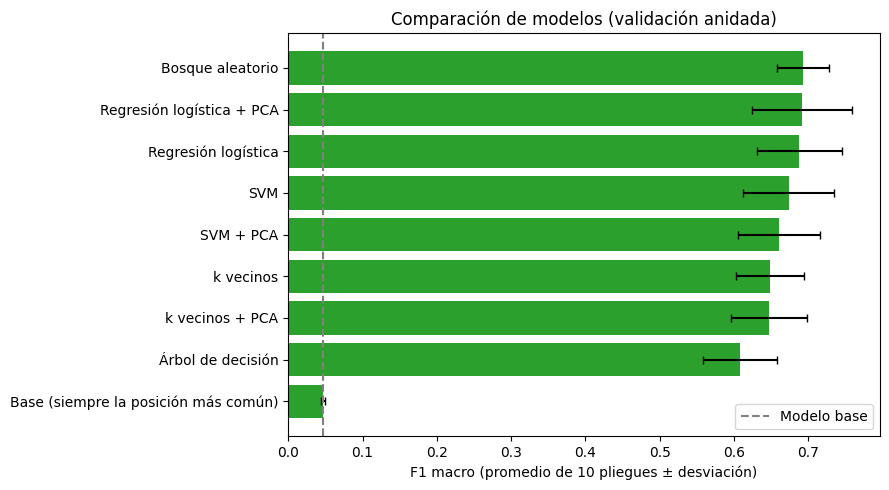

In [6]:
filas = []
for nombre, v in validaciones.items():
    p = v["pliegues"]
    frecuentes = Counter(v["parametros"]).most_common(1)
    filas.append({
        "modelo": nombre,
        "aciertos": p["aciertos"].mean(),
        "aciertos_balanceados": p["aciertos_balanceados"].mean(),
        "f1_macro": p["f1_macro"].mean(),
        "f1_macro_desv": p["f1_macro"].std(),
        "top2": p["top2"].mean(),
        "perdida_log": p["perdida_log"].mean(),
        "parametros_mas_frecuentes": frecuentes[0][0] if frecuentes else "sin ajuste",
    })

resultados = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
mostrar = resultados.drop(columns="parametros_mas_frecuentes").copy()
mostrar[["aciertos", "aciertos_balanceados", "f1_macro", "f1_macro_desv", "top2", "perdida_log"]] = \
    mostrar[["aciertos", "aciertos_balanceados", "f1_macro", "f1_macro_desv", "top2", "perdida_log"]].round(3)
display(mostrar)

NOMBRE_BASE = MODELOS[0]
candidatos = resultados[resultados["modelo"] != NOMBRE_BASE].reset_index(drop=True)
MAYOR = candidatos.loc[0, "modelo"]
f1_mayor = float(candidatos.loc[0, "f1_macro"])
f1_base = float(resultados.loc[resultados["modelo"] == NOMBRE_BASE, "f1_macro"].iloc[0])

# Regla de parsimonia (fijada de antemano): entre los modelos a menos de 0.01 de F1 macro del que más saca,
# se elige el más simple y fácil de explicar.
TOLERANCIA = 0.01
ORDEN_SIMPLICIDAD = [
    "Regresión logística", "Árbol de decisión", "k vecinos", "Regresión logística + PCA",
    "k vecinos + PCA", "SVM", "SVM + PCA", "Bosque aleatorio",
]
cercanos = candidatos[candidatos["f1_macro"] >= f1_mayor - TOLERANCIA]["modelo"].tolist()
MEJOR = min(cercanos, key=ORDEN_SIMPLICIDAD.index)
fila_elegida = candidatos[candidatos["modelo"] == MEJOR].iloc[0]
f1_mejor = float(fila_elegida["f1_macro"])

print(f"Modelo con mayor F1 macro: {MAYOR} ({f1_mayor:.3f}). El modelo base saca {f1_base:.3f}.")
print(f"Modelos a menos de {TOLERANCIA} del mayor (con estos datos no se pueden distinguir): {cercanos}")
print(f"Modelo elegido por parsimonia (el más simple de ellos): {MEJOR} (F1 macro {f1_mejor:.3f})")
print("Hiperparámetros más frecuentes del elegido:", fila_elegida["parametros_mas_frecuentes"])

orden = resultados.sort_values("f1_macro")
plt.figure(figsize=(9, 5))
plt.barh(orden["modelo"], orden["f1_macro"], xerr=orden["f1_macro_desv"], color="tab:green", capsize=3)
plt.axvline(f1_base, linestyle="--", color="gray", label="Modelo base")
plt.xlabel("F1 macro (promedio de 10 pliegues ± desviación)")
plt.title("Comparación de modelos (validación anidada)")
plt.legend()
plt.tight_layout()
plt.show()

### ¿Sirve PCA?
*Qué hace:* compara cada modelo **sin PCA** contra **con PCA** (resumiendo las variables en 4, 6 u 8 componentes, elegido por la validación interna). Si PCA no mejora, no vale la pena perder la interpretación de las habilidades originales.

In [7]:
pares = [("k vecinos", "k vecinos + PCA"), ("Regresión logística", "Regresión logística + PCA"), ("SVM", "SVM + PCA")]
tabla_pca = pd.DataFrame([
    {
        "modelo": sin,
        "f1_sin_pca": validaciones[sin]["pliegues"]["f1_macro"].mean(),
        "f1_con_pca": validaciones[con]["pliegues"]["f1_macro"].mean(),
    }
    for sin, con in pares
])
tabla_pca["diferencia"] = tabla_pca["f1_con_pca"] - tabla_pca["f1_sin_pca"]
display(tabla_pca.round(3))

mejora_pca = float(tabla_pca["diferencia"].mean())
if mejora_pca >= UMBRAL_MEJORA:
    texto_pca = f"PCA mejora el F1 macro en promedio {mejora_pca:+.3f}."
elif mejora_pca <= -UMBRAL_MEJORA:
    texto_pca = f"PCA empeora el F1 macro en promedio {mejora_pca:+.3f}: se pierde información al resumir las habilidades."
else:
    texto_pca = f"PCA no cambia de forma apreciable el F1 macro (diferencia promedio {mejora_pca:+.3f}); no justifica perder la interpretación."
print(texto_pca)

,modelo,f1_sin_pca,f1_con_pca,diferencia
0,k vecinos,0.648,0.647,-0.001
1,Regresión logística,0.688,0.692,0.004
2,SVM,0.674,0.661,-0.013


PCA no cambia de forma apreciable el F1 macro (diferencia promedio -0.003); no justifica perder la interpretación.


## 4. El modelo elegido a fondo

*Qué hace:* repite la validación del modelo elegido, ahora también calculando **qué variables importan** (permutación: se baraja una variable en las personas de prueba y se ve cuánto empeora el modelo). Con esos resultados:

- **Por posición:** precisión (de las que el modelo llama "X", cuántas lo son), sensibilidad (de las que realmente son "X", cuántas detecta) y F1.
- **Matriz de confusión:** en qué posiciones se confunde (primera repetición de la validación, cada persona aparece una vez).

Tiempo: 0.1 min
F1 macro (igual que en la tabla): 0.688 vs 0.688


,posicion,personas,precision,sensibilidad,f1
0,Portero,32,0.87,0.81,0.84
1,Defensa central,53,0.72,0.68,0.70
2,Lateral,41,0.54,0.71,0.61
3,Mediocampista defensivo,39,0.58,0.56,0.57
4,Mediocampista ofensivo,37,0.72,0.57,0.64
5,Extremo,27,0.80,0.74,0.77
6,Delantero,43,0.76,0.81,0.79


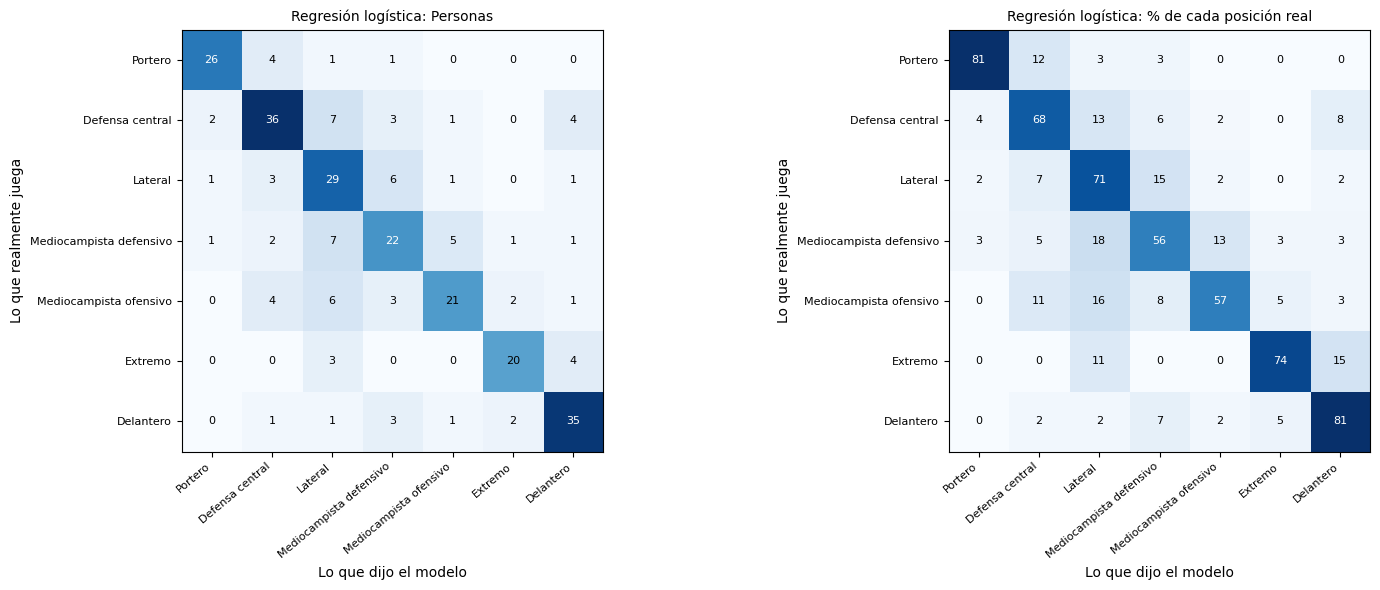

Confusiones más frecuentes (real → dijo el modelo):
  Defensa central → Lateral: 7 personas
  Mediocampista defensivo → Lateral: 7 personas
  Lateral → Mediocampista defensivo: 6 personas
  Mediocampista ofensivo → Lateral: 6 personas
  Mediocampista defensivo → Mediocampista ofensivo: 5 personas


In [8]:
inicio = time.perf_counter()
mejor_val = validar(MEJOR, datos, NUMERICAS, CATEGORICAS, importancia=True)
print(f"Tiempo: {(time.perf_counter() - inicio) / 60:.1f} min")
print(f"F1 macro (igual que en la tabla): {mejor_val['pliegues']['f1_macro'].mean():.3f} vs {f1_mejor:.3f}")

verdad, predicho = mejor_val["verdad"], mejor_val["predicho"]
precision, sensibilidad, f1_clase, soporte = precision_recall_fscore_support(
    verdad, predicho, labels=ORDEN_POSICION, zero_division=0)
por_clase = pd.DataFrame({
    "posicion": ORDEN_POSICION, "personas": soporte, "precision": precision,
    "sensibilidad": sensibilidad, "f1": f1_clase,
})
display(por_clase.round(2))

matriz = confusion_matrix(verdad, predicho, labels=ORDEN_POSICION)
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True) * 100

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for eje, valores, titulo, formato in [
    (ejes[0], matriz, "Personas", "{:.0f}"),
    (ejes[1], matriz_pct, "% de cada posición real", "{:.0f}"),
]:
    imagen = eje.imshow(valores, cmap="Blues")
    eje.set_xticks(range(7))
    eje.set_yticks(range(7))
    eje.set_xticklabels(ORDEN_POSICION, rotation=40, ha="right", fontsize=8)
    eje.set_yticklabels(ORDEN_POSICION, fontsize=8)
    eje.set_xlabel("Lo que dijo el modelo")
    eje.set_ylabel("Lo que realmente juega")
    eje.set_title(f"{MEJOR}: {titulo}", fontsize=10)
    for i in range(7):
        for j in range(7):
            color = "white" if valores[i, j] > valores.max() * 0.6 else "black"
            eje.text(j, i, formato.format(valores[i, j]), ha="center", va="center", fontsize=8, color=color)
plt.tight_layout()
plt.show()

fuera = [(ORDEN_POSICION[i], ORDEN_POSICION[j], int(matriz[i, j])) for i in range(7) for j in range(7) if i != j]
fuera = sorted(fuera, key=lambda t: -t[2])[:5]
print("Confusiones más frecuentes (real → dijo el modelo):")
for real, dijo, n in fuera:
    print(f"  {real} → {dijo}: {n} personas")

### ¿Qué variables pesan más?
*Qué hace:* muestra cuánto baja el F1 macro cuando se "estropea" cada variable en las personas de prueba. Un valor alto = el modelo depende mucho de esa variable. **No es causalidad**: con autoevaluaciones, solo indica qué autoevaluaciones ayudan a distinguir posiciones.

,variable,importancia,desviacion
0,Juego aéreo,0.111,0.033
1,Definición,0.098,0.034
2,Defensa,0.093,0.036
3,Reflejos,0.090,0.032
4,Regate,0.087,0.042
5,Velocidad,0.085,0.026
6,Pase,0.069,0.031
7,Resistencia,0.017,0.027
8,Control del balón,0.014,0.014
9,Posicionamiento,0.012,0.016


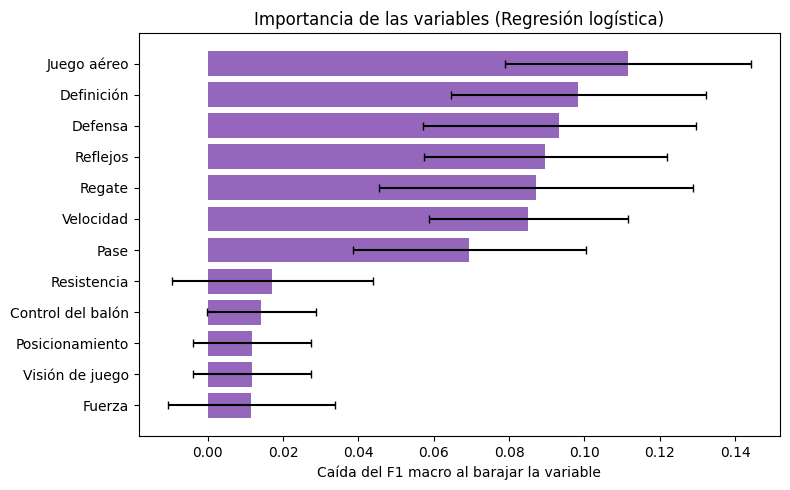

In [9]:
importancia = pd.DataFrame({
    "variable": [NOMBRES[c] for c in COLUMNAS_ENTRADA],
    "importancia": mejor_val["importancia"].mean(axis=0),
    "desviacion": mejor_val["importancia"].std(axis=0),
}).sort_values("importancia", ascending=False).reset_index(drop=True)
display(importancia.round(3))

orden = importancia.sort_values("importancia")
plt.figure(figsize=(8, 5))
plt.barh(orden["variable"], orden["importancia"], xerr=orden["desviacion"], color="tab:purple", capsize=3)
plt.xlabel("Caída del F1 macro al barajar la variable")
plt.title(f"Importancia de las variables ({MEJOR})")
plt.tight_layout()
plt.show()

## 5. ¿Podemos mostrar probabilidades en la aplicación?

*Qué hace:* un modelo puede decir "Delantero, 70 %". Eso solo es útil si **cuando dice 70 %, acierta alrededor del 70 % de las veces** (calibración). Se compara la confianza del modelo con su acierto real y se calcula el **error de calibración esperado (ECE)**: el promedio de la diferencia entre ambos.

**Criterio que fijamos:** mostramos la probabilidad por posición **solo si el ECE es de 0.08 o menos**. Si no, la aplicación mostrará la posición más probable y las dos siguientes **sin presentar los porcentajes como si fueran exactos**.

,tramo,personas,confianza_media,aciertos_reales
0,"[0.0, 0.3)",31,0.26,0.35
1,"[0.3, 0.4)",56,0.35,0.41
2,"[0.4, 0.5)",30,0.44,0.60
3,"[0.5, 0.6)",49,0.56,0.86
4,"[0.6, 0.8)",69,0.69,0.94
5,"[0.8, 1.0)",37,0.90,0.81


ECE = 0.172 (criterio: <= 0.08) -> mostrar probabilidades en la aplicación: NO


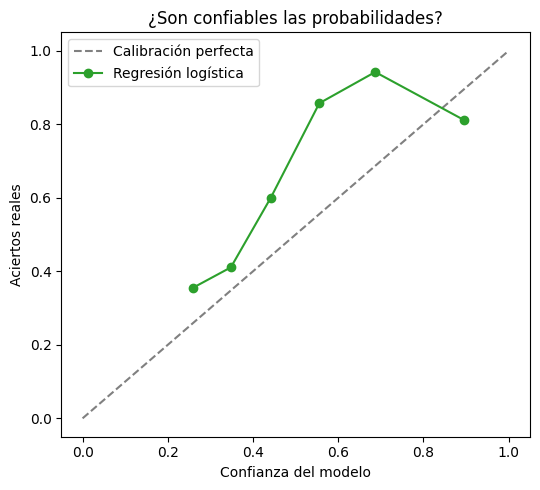

In [10]:
UMBRAL_ECE = 0.08
confianza = mejor_val["proba"].max(axis=1)
acierta = (mejor_val["predicho"] == mejor_val["verdad"]).astype(float)
cortes = [0.0, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0001]
tramo = pd.cut(confianza, bins=cortes, right=False)

calibracion = pd.DataFrame({"tramo": tramo, "confianza": confianza, "acierta": acierta}).groupby("tramo", observed=True).agg(
    personas=("acierta", "size"), confianza_media=("confianza", "mean"), aciertos_reales=("acierta", "mean"),
).reset_index()
calibracion["tramo"] = calibracion["tramo"].astype(str)
ECE = float((calibracion["personas"] / calibracion["personas"].sum() * (calibracion["aciertos_reales"] - calibracion["confianza_media"]).abs()).sum())
MOSTRAR_PROBABILIDADES = bool(ECE <= UMBRAL_ECE)
display(calibracion.round(2))
print(f"ECE = {ECE:.3f} (criterio: <= {UMBRAL_ECE}) -> mostrar probabilidades en la aplicación: {'SÍ' if MOSTRAR_PROBABILIDADES else 'NO'}")

plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
plt.plot(calibracion["confianza_media"], calibracion["aciertos_reales"], "o-", color="tab:green", label=MEJOR)
plt.xlabel("Confianza del modelo")
plt.ylabel("Aciertos reales")
plt.title("¿Son confiables las probabilidades?")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Sensibilidad: ¿cambian los resultados si quitamos casos dudosos?

*Qué hace:* en la limpieza **marcamos** casos dudosos sin borrarlos. Aquí comprobamos, con el mejor modelo, si el resultado depende de ellos:

- **Todos:** la base completa.
- **Sin casos marcados:** quita duplicados posibles (se conserva la primera respuesta), respuestas "en línea recta" y edades atípicas.
- **Sin menores de 18 años.**

Si los resultados son parecidos, los casos dudosos no están moviendo las conclusiones.

In [11]:
escenarios = {
    "Todos": pd.Series(True, index=datos.index),
    "Sin casos marcados (duplicados repetidos, línea recta, edad atípica)":
        (datos["duplicado_repetida"] == 0) & (datos["linea_recta"] == 0) & (datos["edad_atipica"] == 0),
    "Sin menores de 18 años": datos["menor_18"] == 0,
}

filas = []
for escenario, mascara in escenarios.items():
    if escenario == "Todos":
        v = mejor_val
    else:
        v = validar(MEJOR, datos[mascara], NUMERICAS, CATEGORICAS)
    p = v["pliegues"]
    filas.append({
        "escenario": escenario, "personas": int(mascara.sum()),
        "aciertos": p["aciertos"].mean(), "f1_macro": p["f1_macro"].mean(), "f1_macro_desv": p["f1_macro"].std(),
    })
sensibilidad = pd.DataFrame(filas)
display(sensibilidad.round(3))

rango = float(sensibilidad["f1_macro"].max() - sensibilidad["f1_macro"].min())
print(f"Diferencia máxima de F1 macro entre escenarios: {rango:.3f}")

,escenario,personas,aciertos,f1_macro,f1_macro_desv
0,Todos,272,0.684,0.688,0.057
1,"Sin casos marcados (duplicados repetidos, líne...",260,0.687,0.682,0.109
2,Sin menores de 18 años,239,0.651,0.652,0.092


Diferencia máxima de F1 macro entre escenarios: 0.036


## 7. Exploración no supervisada: K-means

*Qué hace:* **sin usar la posición**, agrupa a las personas según sus 12 habilidades y luego compara los grupos con las posiciones reales. Sirve para ver si las habilidades, por sí solas, "dibujan" las posiciones.

- **Distancia:** euclidiana, sobre las habilidades **estandarizadas** (para que todas pesen igual).
- **Número de grupos:** **no lo fijamos de antemano**. Probamos de 2 a 10 y usamos la **silueta** (qué tan separados están los grupos; de −1 a 1; mejor mientras más alta) y la **inercia** (codo).
- **Comparación con las posiciones:** índice de Rand ajustado (ARI: 0 = sin relación, 1 = idéntico) e información mutua normalizada (NMI).

,k,inercia,silueta,rand_ajustado,nmi
0,2,2381.380,0.224,0.033,0.056
1,3,2013.255,0.204,0.120,0.215
2,4,1782.598,0.185,0.110,0.197
3,5,1657.512,0.172,0.098,0.208
4,6,1526.118,0.183,0.139,0.266
5,7,1417.947,0.184,0.121,0.249
6,8,1334.551,0.193,0.194,0.353
7,9,1249.062,0.192,0.187,0.346
8,10,1203.931,0.179,0.161,0.311


k con mayor silueta: 2 (silueta 0.22; ARI 0.03; NMI 0.06)
Con k = 7 (una por posición): silueta 0.18; ARI 0.12; NMI 0.25


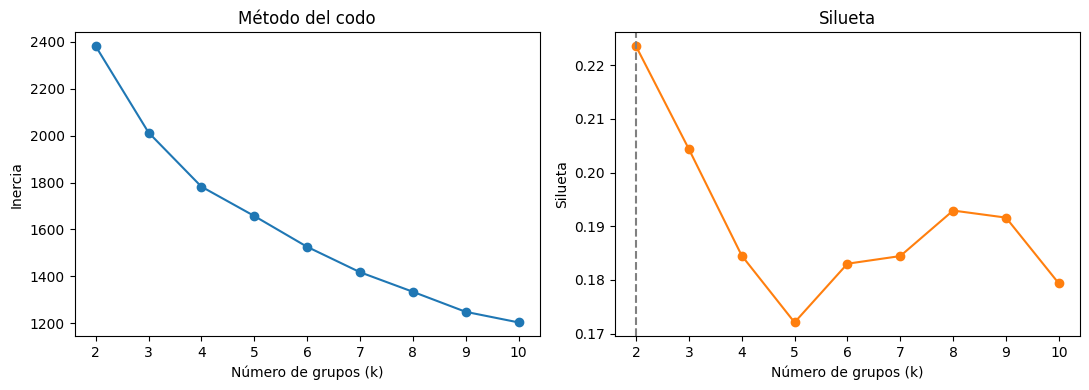

Grupos (k = 2) contra posiciones reales:


posicion,Portero,Defensa central,Lateral,Mediocampista defensivo,Mediocampista ofensivo,Extremo,Delantero
grupo,,,,,,,
0,26,35,22,8,13,9,21
1,6,18,19,31,24,18,22


In [12]:
imputador = SimpleImputer(strategy="median")
Xk = StandardScaler().fit_transform(imputador.fit_transform(datos[HABILIDADES]))
posiciones_reales = datos["posicion"].to_numpy()

filas = []
for k in range(2, 11):
    agrupador = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Xk)
    filas.append({
        "k": k, "inercia": agrupador.inertia_, "silueta": silhouette_score(Xk, agrupador.labels_),
        "rand_ajustado": adjusted_rand_score(posiciones_reales, agrupador.labels_),
        "nmi": normalized_mutual_info_score(posiciones_reales, agrupador.labels_),
    })
kmeans = pd.DataFrame(filas)
display(kmeans.round(3))

K_ELEGIDO = int(kmeans.loc[kmeans["silueta"].idxmax(), "k"])
fila_k = kmeans[kmeans["k"] == K_ELEGIDO].iloc[0]
fila_7 = kmeans[kmeans["k"] == 7].iloc[0]
print(f"k con mayor silueta: {K_ELEGIDO} (silueta {fila_k['silueta']:.2f}; ARI {fila_k['rand_ajustado']:.2f}; NMI {fila_k['nmi']:.2f})")
print(f"Con k = 7 (una por posición): silueta {fila_7['silueta']:.2f}; ARI {fila_7['rand_ajustado']:.2f}; NMI {fila_7['nmi']:.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(kmeans["k"], kmeans["inercia"], "o-")
ejes[0].set_xlabel("Número de grupos (k)")
ejes[0].set_ylabel("Inercia")
ejes[0].set_title("Método del codo")
ejes[1].plot(kmeans["k"], kmeans["silueta"], "o-", color="tab:orange")
ejes[1].axvline(K_ELEGIDO, linestyle="--", color="gray")
ejes[1].set_xlabel("Número de grupos (k)")
ejes[1].set_ylabel("Silueta")
ejes[1].set_title("Silueta")
plt.tight_layout()
plt.show()

agrupador = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=0).fit(Xk)
cruce_k = pd.crosstab(pd.Series(agrupador.labels_, name="grupo"), pd.Series(posiciones_reales, name="posicion"))[ORDEN_POSICION]
print(f"Grupos (k = {K_ELEGIDO}) contra posiciones reales:")
display(cruce_k)

## 8. Modelo final y guardado

*Qué hace:* entrena el mejor modelo con **todas** las personas (buscando sus hiperparámetros con una validación de 5 pliegues), lo guarda en `modelo_posicion.joblib` y escribe `modelo_metadata.json` con todo lo que la aplicación necesita (variables de entrada, clases, versión de scikit-learn, métricas). Luego **vuelve a cargar el archivo y comprueba** que da las mismas predicciones.

**Importante:** la métrica que vale es la de la validación anidada (sección 3). Este modelo final se entrena con todos los datos para la aplicación y no se evalúa con ellos.

In [13]:
final = estimador(MEJOR, NUMERICAS, CATEGORICAS)
if hasattr(final, "cv"):
    final.cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
final.fit(datos[COLUMNAS_ENTRADA], datos["posicion"].to_numpy())
modelo_final = final.best_estimator_ if hasattr(final, "best_estimator_") else final
parametros_finales = final.best_params_ if hasattr(final, "best_params_") else {}
print("Hiperparámetros del modelo final:", parametros_finales)

os.makedirs("resultados_modelado", exist_ok=True)
RUTA_MODELO = os.path.join("resultados_modelado", "modelo_posicion.joblib")
joblib.dump(modelo_final, RUTA_MODELO)

# Comprobación: cargarlo de nuevo y comparar las probabilidades.
recargado = joblib.load(RUTA_MODELO)
muestra = datos[COLUMNAS_ENTRADA].head(25)
assert np.allclose(modelo_final.predict_proba(muestra), recargado.predict_proba(muestra))
assert list(recargado.classes_) == CLASES
proba_prueba = recargado.predict_proba(muestra)
assert np.allclose(proba_prueba.sum(axis=1), 1.0)
print("Modelo guardado y recargado: OK")

# Una persona con valores vacíos ("No sé") también debe poder predecirse.
con_vacios = datos[COLUMNAS_ENTRADA].head(1).copy()
for columna in HABILIDADES[:2]:
    con_vacios[columna] = np.nan
assert recargado.predict_proba(con_vacios).shape == (1, len(CLASES))
print("Predicción con datos vacíos: OK")

Hiperparámetros del modelo final: {'modelo__C': 0.1}
Modelo guardado y recargado: OK
Predicción con datos vacíos: OK


In [14]:
p_mejor = validaciones[MEJOR]["pliegues"]
metadatos = {
    "titulo": "Predicción de la posición habitual de un jugador de fútbol",
    "modelo": MEJOR,
    "hiperparametros": {k: (None if v is None else (v if isinstance(v, (int, float, str)) else str(v))) for k, v in parametros_finales.items()},
    "conjunto_variables": CONJUNTO_ELEGIDO,
    "columnas_entrada": COLUMNAS_ENTRADA,
    "columnas_numericas": NUMERICAS,
    "columnas_categoricas": CATEGORICAS,
    "clases": [str(c) for c in recargado.classes_],
    "personas_entrenamiento": int(len(datos)),
    "validacion": "Validación cruzada estratificada 5x2 con búsqueda de hiperparámetros anidada (3 pliegues)",
    "metricas_validacion": {
        "aciertos": round(float(p_mejor["aciertos"].mean()), 4),
        "aciertos_balanceados": round(float(p_mejor["aciertos_balanceados"].mean()), 4),
        "f1_macro": round(float(p_mejor["f1_macro"].mean()), 4),
        "top2": round(float(p_mejor["top2"].mean()), 4),
        "base_aciertos": round(float(base), 4),
        "azar": round(float(azar), 4),
    },
    "ece": round(float(ECE), 4),
    "umbral_ece": UMBRAL_ECE,
    "mostrar_probabilidades": MOSTRAR_PROBABILIDADES,
    "opciones": {
        "habilidad_minimo": 1, "habilidad_maximo": 5,
        "nivel": ["Escolar", "Recreativo (por diversión)", "Amateur en un equipo organizado", "Competitivo o semiprofesional", "Profesional"],
        "tiempo_juego": ["Menos de 1 año", "De 1 a 2 años", "De 3 a 5 años", "De 6 a 10 años", "Más de 10 años"],
        "horas_semana": ["Actualmente, ninguna", "De 1 a 2 horas", "De 3 a 5 horas", "De 6 a 8 horas", "De 9 a 12 horas", "Más de 12 horas"],
    },
    "versiones": {
        "python": platform.python_version(), "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__,
    },
}
with open(os.path.join("resultados_modelado", "modelo_metadata.json"), "w", encoding="utf-8") as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)
print(json.dumps(metadatos["metricas_validacion"], ensure_ascii=False))

{"aciertos": 0.6841, "aciertos_balanceados": 0.6885, "f1_macro": 0.6878, "top2": 0.8274, "base_aciertos": 0.1949, "azar": 0.1429}


## 9. Guardar los resultados
*Qué hace:* guarda todas las tablas en la carpeta `resultados_modelado` y las empaqueta en `Resultados_Modelado.zip`. Esos archivos alimentan la base de datos (cuaderno 04), el tablero y la aplicación.

In [15]:
salida = "resultados_modelado"

resultados.to_csv(f"{salida}/Resultados_Modelos.csv", index=False, encoding="utf-8-sig")
comparacion.to_csv(f"{salida}/Comparacion_Variables.csv", index=False, encoding="utf-8-sig")
tabla_pca.to_csv(f"{salida}/Comparacion_PCA.csv", index=False, encoding="utf-8-sig")
por_clase.to_csv(f"{salida}/Resultados_Por_Posicion.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(matriz, index=ORDEN_POSICION, columns=ORDEN_POSICION).rename_axis("real").reset_index().to_csv(
    f"{salida}/Matriz_Confusion.csv", index=False, encoding="utf-8-sig")
importancia.to_csv(f"{salida}/Importancia_Variables.csv", index=False, encoding="utf-8-sig")
calibracion.to_csv(f"{salida}/Calibracion.csv", index=False, encoding="utf-8-sig")
sensibilidad.to_csv(f"{salida}/Sensibilidad.csv", index=False, encoding="utf-8-sig")
kmeans.to_csv(f"{salida}/Resultados_KMeans.csv", index=False, encoding="utf-8-sig")
cruce_k.reset_index().to_csv(f"{salida}/Cruce_Grupos_Posicion.csv", index=False, encoding="utf-8-sig")

fila_mejor = resultados[resultados["modelo"] == MEJOR].iloc[0]
resumen = pd.DataFrame({
    "concepto": [
        "personas", "posiciones", "azar_pct", "base_aciertos_pct", "base_f1_macro", "conjunto_variables",
        "mejor_modelo", "modelo_mayor_f1", "mejor_aciertos_pct", "mejor_aciertos_balanceados_pct", "mejor_f1_macro",
        "mejor_f1_macro_desv", "mejor_top2_pct", "ece", "mostrar_probabilidades", "mejora_experiencia_f1",
        "mejora_pca_f1", "k_elegido_silueta", "silueta_k_elegido", "rand_ajustado_k_elegido",
        "rand_ajustado_k7", "nmi_k7", "version_scikit_learn",
    ],
    "valor": [
        len(datos), len(CLASES), round(100 * azar, 1), round(100 * base, 1), round(f1_base, 4), CONJUNTO_ELEGIDO,
        MEJOR, MAYOR, round(100 * fila_mejor["aciertos"], 1), round(100 * fila_mejor["aciertos_balanceados"], 1),
        round(float(fila_mejor["f1_macro"]), 4), round(float(fila_mejor["f1_macro_desv"]), 4),
        round(100 * fila_mejor["top2"], 1), round(ECE, 4), MOSTRAR_PROBABILIDADES, round(mejora, 4),
        round(mejora_pca, 4), K_ELEGIDO, round(float(fila_k["silueta"]), 4), round(float(fila_k["rand_ajustado"]), 4),
        round(float(fila_7["rand_ajustado"]), 4), round(float(fila_7["nmi"]), 4), sklearn.__version__,
    ],
})
resumen["valor"] = resumen["valor"].astype(str)
resumen.to_csv(f"{salida}/Resumen_Modelado.csv", index=False, encoding="utf-8-sig")

shutil.make_archive("Resultados_Modelado", "zip", salida)
print("Archivos en", salida + ":", sorted(os.listdir(salida)))
if EN_COLAB:
    files.download("Resultados_Modelado.zip")

Archivos en resultados_modelado: ['Calibracion.csv', 'Comparacion_PCA.csv', 'Comparacion_Variables.csv', 'Cruce_Grupos_Posicion.csv', 'Importancia_Variables.csv', 'Matriz_Confusion.csv', 'Resultados_KMeans.csv', 'Resultados_Modelos.csv', 'Resultados_Por_Posicion.csv', 'Resumen_Modelado.csv', 'Sensibilidad.csv', 'modelo_metadata.json', 'modelo_posicion.joblib']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Resumen de esta ejecución
*Qué hace:* imprime las cifras reales de esta ejecución, para que los documentos, el tablero y la aplicación usen **exactamente** estos números.

In [16]:
print("RESUMEN DE LA EJECUCIÓN")
print("-" * 60)
print(f"Personas: {len(datos)} | Posiciones: {len(CLASES)} | Variables: {CONJUNTO_ELEGIDO} ({len(COLUMNAS_ENTRADA)})")
print(f"Azar: {azar:.1%} | Base (siempre la más común): {base:.1%} aciertos, F1 macro {f1_base:.3f}")
print(f"Mejora al agregar experiencia: {mejora:+.3f} (umbral {UMBRAL_MEJORA})")
print("Modelos (F1 macro, aciertos, aciertos balanceados):")
for fila in resultados.itertuples():
    print(f"  {fila.modelo:40} {fila.f1_macro:.3f} | {fila.aciertos:.3f} | {fila.aciertos_balanceados:.3f}")
print(f"Elegido: {MEJOR} -> F1 macro {fila_mejor['f1_macro']:.3f} ± {fila_mejor['f1_macro_desv']:.3f}, "
      f"aciertos {fila_mejor['aciertos']:.3f}, top-2 {fila_mejor['top2']:.3f}")
print(f"Modelo con mayor F1 macro: {MAYOR} ({f1_mayor:.3f}) | a menos de {TOLERANCIA} de él: {cercanos}")
print(f"PCA: {texto_pca}")
print("Por posición (F1):", ", ".join(f"{r.posicion} {r.f1:.2f}" for r in por_clase.itertuples()))
print("Confusiones más frecuentes:", "; ".join(f"{a} → {b} ({n})" for a, b, n in fuera))
print("Variables más importantes:", ", ".join(f"{r.variable} ({r.importancia:.3f})" for r in importancia.head(4).itertuples()))
print(f"Calibración: ECE {ECE:.3f} -> mostrar probabilidades: {'SÍ' if MOSTRAR_PROBABILIDADES else 'NO'}")
print("Sensibilidad (F1 macro):", "; ".join(f"{r.escenario.split(' (')[0]} {r.f1_macro:.3f} (n = {r.personas})" for r in sensibilidad.itertuples()))
print(f"K-means: k = {K_ELEGIDO} (silueta {fila_k['silueta']:.2f}); ARI con k = {K_ELEGIDO}: {fila_k['rand_ajustado']:.2f}; con k = 7: {fila_7['rand_ajustado']:.2f}")
print(f"Modelo final: hiperparámetros {parametros_finales} | scikit-learn {sklearn.__version__}")

RESUMEN DE LA EJECUCIÓN
------------------------------------------------------------
Personas: 272 | Posiciones: 7 | Variables: Solo habilidades (12)
Azar: 14.3% | Base (siempre la más común): 19.5% aciertos, F1 macro 0.047
Mejora al agregar experiencia: -0.004 (umbral 0.01)
Modelos (F1 macro, aciertos, aciertos balanceados):
  Bosque aleatorio                         0.693 | 0.686 | 0.689
  Regresión logística + PCA                0.692 | 0.688 | 0.693
  Regresión logística                      0.688 | 0.684 | 0.689
  SVM                                      0.674 | 0.664 | 0.671
  SVM + PCA                                0.661 | 0.652 | 0.658
  k vecinos                                0.648 | 0.640 | 0.643
  k vecinos + PCA                          0.647 | 0.645 | 0.648
  Árbol de decisión                        0.608 | 0.607 | 0.608
  Base (siempre la posición más común)     0.047 | 0.195 | 0.143
Elegido: Regresión logística -> F1 macro 0.688 ± 0.057, aciertos 0.684, top-2 0.827
Mod

## Conclusiones

Las **cifras** están en las tablas de arriba y en el resumen de esta ejecución. Las conclusiones de método son estas:

- Es un problema de **aprendizaje supervisado de clasificación con siete clases**, y los datos lo permiten: cada posición tiene suficientes personas y no se fusionó ninguna.
- Los modelos se compararon con **validación anidada** y siempre contra un **modelo base**. La métrica con la que se eligió el mejor es el **F1 macro**.
- Cuando varios modelos quedan a menos de 0.01 de F1 macro, **no es posible distinguirlos** con estos datos (la variación entre pliegues es mayor). Por eso fijamos una **regla de parsimonia**: se elige el más simple y fácil de explicar entre ellos. Elegirlo no significa que sea claramente superior a los demás.
- **PCA** se probó con y sin; la decisión se tomó con los resultados, recordando que PCA hace más difícil explicar cada habilidad.
- El **K-means** se usó solo para explorar, con el número de grupos elegido por silueta y comparado con las posiciones reales.
- Las probabilidades se muestran en la aplicación **solo si** el criterio de calibración (ECE) lo permite.
- **Limitaciones:** las habilidades son autoevaluaciones (cada persona se describe según su posición), la muestra es sobre todo de jugadores recreativos y el resultado no se puede generalizar a futbolistas profesionales.

**Siguiente paso:** base de datos (cuaderno 04), aplicación web y tablero.